In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

In [5]:
# 1. Load the Iris dataset
data = pd.read_csv("Iris.csv")

# Check dataset
print("Dataset:")
print(data.head())

print("\nColumns:")
print(data.columns)


Dataset:
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa

Columns:
Index(['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='str')


In [6]:
# 2. Remove Id column if present
if "Id" in data.columns:
    data = data.drop("Id", axis=1)


In [7]:
# 3. Separate features and target
X = data.iloc[:, :-1]
y = data.iloc[:, -1]

In [8]:
# 4. Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=2,
    # stratify=y
)


In [9]:
# 5. Define SVM kernels
kernels = {
    "Linear": SVC(kernel="linear"),
    "Sigmoid": SVC(kernel="sigmoid"),
    "RBF": SVC(kernel="rbf"),
    "Gaussian": SVC(kernel="rbf")
}


In [10]:
# 6. Train models and calculate accuracy
accuracies = {}

for kernel_name, model in kernels.items():

    # Train model
    model.fit(X_train, y_train)

    # Predict test data
    y_pred = model.predict(X_test)

    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)

    accuracies[kernel_name] = accuracy

    print(
        f"{kernel_name} Kernel Accuracy: "
        f"{accuracy * 100:.2f}%"
    )


Linear Kernel Accuracy: 100.00%
Sigmoid Kernel Accuracy: 28.89%
RBF Kernel Accuracy: 97.78%
Gaussian Kernel Accuracy: 97.78%


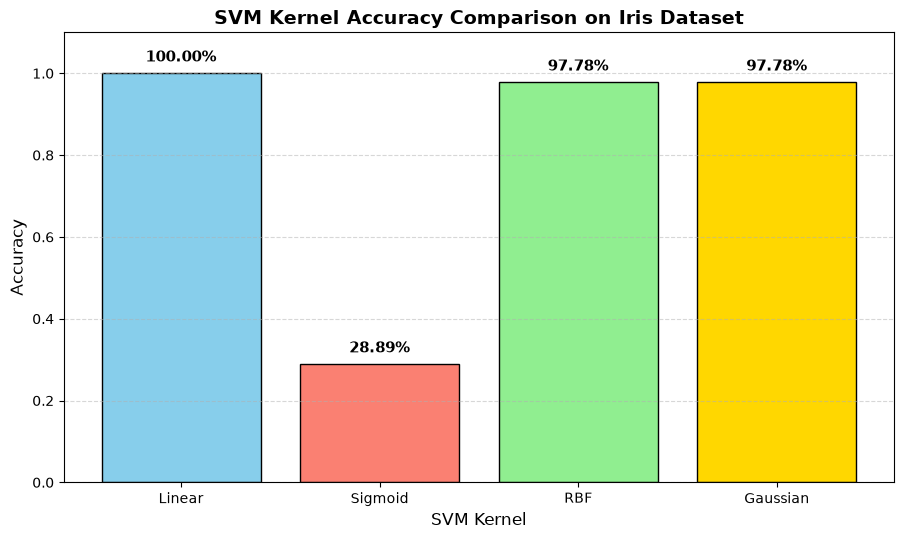

In [11]:
# 7. Plot kernel accuracies
plt.figure(figsize=(10, 6))

bars = plt.bar(
    accuracies.keys(),
    accuracies.values(),
    color=["skyblue", "salmon", "lightgreen", "gold"],
    edgecolor="black"
)

plt.title(
    "SVM Kernel Accuracy Comparison on Iris Dataset",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("SVM Kernel", fontsize=12)
plt.ylabel("Accuracy", fontsize=12)

plt.ylim(0, 1.1)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.5
)

# Display accuracy values
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.02,
        f"{height * 100:.2f}%",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

# Adjust margins
plt.subplots_adjust(
    left=0.12,
    right=0.95,
    bottom=0.15,
    top=0.90
)

plt.show()